# Розпізнавання психологічного стресу та фізичного навантаження за сигналами браслета: класична ML, глибока мережа і Transformer

## 1. Постановка задачі

Багатокласова класифікація часових рядів. Вхід X: 30-секундне вікно сигналів браслета Empatica E4 (EDA, BVP, HR, TEMP, ACC). Ціль y: стан людини у вікні.

- 0: спокій
- 1: психологічний стрес (когнітивні й емоційні завдання)
- 2: фізичне навантаження (велотренажер)

Задача складна тим, що пульс і провідність шкіри ростуть і при стресі, і при навантаженні, а браслет дає лише периферійні сигнали низької якості.

Порівнюються три рівні моделей на одній задачі, одному датасеті й одному протоколі: XGBoost над ручними ознаками, одновимірна згорткова мережа над сирими сигналами і попередньо навчений Transformer для часових рядів MOMENT-1. Порівняння за якістю і за ціною: час підготовки й навчання, inference, пам'ять, параметри, потреба в GPU.


## 2. Датасет

Wearable Device Dataset from Induced Stress and Structured Exercise Sessions, v1.0.1, PhysioNet (DOI 10.13026/zzf8-xv61), ліцензія ODC-By 1.0. Описаний у Hongn et al., Scientific Data 12:520 (2025).

- 36 здорових дорослих, до трьох сесій на людину: стрес-протокол (базовий рівень, завдання, відпочинки; варіанти V1 і V2), аеробне тренування (~35 хв), анаеробне (спринти Вінгейта).
- Сигнали: EDA 4 Гц, BVP 64 Гц, HR 1 Гц, TEMP 4 Гц, ACC 32 Гц. Межі етапів у `tags.csv`.
- Після сегментації: 3758 вікон по 30 с від 36 учасників (спокій 753, стрес 370, навантаження 2635). Без двох учасників без стрес-сесії: 3592 вікна від 34 учасників.
- Виключені 4 записи з дефектами, зазначеними авторами (дубльовані сигнали, закритий датчик, обірваний запис, запис з одним тегом).

Класи незбалансовані, тому всюди ваги класів, а основна метрика macro-F1.


## 3. Огляд літератури

| Робота | Задача | Дані і split | Модель | Метрики | Результат | Що взято |
|---|---|---|---|---|---|---|
| Hongn et al., 2025, *Scientific Data* 12:520, DOI 10.1038/s41597-025-04845-9 | стрес/спокій; аеробне/спринти; 4 класи | цей самий датасет, 1 приклад = етап протоколу, 10-fold CV з випадковим поділом, oversampling | XGBoost, 49 ознак, скорочених до 13-19 після фільтра кореляції | accuracy, precision, recall, F1 | стрес/спокій 93 % acc, F1 92 %; 4 класи 84 % acc, F1 84 % | набір ознак (HR, тонічна/фазна EDA, IBI, RMSSD, LF, std ACC), друга половина відпочинків, нормалізація в межах учасника |
| Schmidt et al., 2018, ICMI (WESAD), DOI 10.1145/3242969.3242985 | спокій/стрес/розвага; стрес/не стрес | 15 учасників, Empatica E4 + нагрудний датчик, вікна 60 с, leave-one-subject-out | DT, RF, AdaBoost, LDA, kNN над ручними ознаками | accuracy, F1 (macro) | зап'ястя, 3 класи: RF F1 66,3 / acc 76,2; стрес/не стрес: RF F1 86,1 / acc 88,3 | перелік ознак зап'ястя, LOSO як еталон чесної перевірки, macro-F1 для дисбалансу |
| Goswami et al., 2024, ICML, arXiv:2402.03885 (MOMENT) | універсальна foundation-модель для часових рядів: прогноз, класифікація, пошук аномалій | попереднє навчання на зібраному авторами Time Series Pile; класифікація перевірена на архіві UCR | encoder T5 над патчами по 8 відліків, вікно 512, три розміри: Small, Base, Large | accuracy на UCR | у класифікації точніша за 11 із 16 порівнюваних методів без донавчання encoder | готова модель для рівня 3: донавчання замість навчання з нуля |
| Dzieżyc et al., 2020, *Sensors* 20(22):6535, DOI 10.3390/s20226535 | спокій/стрес/розвага (WESAD) | 14 сигналів грудей і зап'ястя, вікна 60 с з кроком 30 с, 5-fold по учасниках | 10 наскрізних глибоких мереж на сирих сигналах: FCN, ResNet, Time-CNN, CNN-LSTM, Inception, … | accuracy, F1, ROC AUC, середнє ± std | найкраща FCN acc 0,79 ± 0,05, F1 0,73 ± 0,07; CNN-LSTM 0,70 / 0,56 | орієнтир для мереж над сирими сигналами, 5-fold по учасниках, звіт mean ± std |
| Kaya et al., 2026, arXiv:2604.12671 | 5 класів: спокій, фізичний стрес і відновлення, психологічний стрес і відновлення | 6 учасників, Empatica E4, вікна 10 хв, leave-one-participant-out | XGBoost, 18 ознак браслета (+ кортизол) | accuracy, recall по класах | лише браслет: 77,8 % acc; recall психологічного стресу 50 %; з кортизолом 94,4 % | підтвердження, що психологічний стрес є найважчим класом саме при розділенні з фізичним |

Пояснення термінів у таблиці. «10-fold CV» означає, що дані поділили на 10 частин і 10 разів навчали модель на 9 частинах, перевіряючи на десятій; «з випадковим поділом» означає, що вікна перемішали без огляду на те, кому вони належать. «Leave-one-subject-out» (LOSO) означає, що по черзі кожного учасника повністю відкладають на перевірку, а на решті навчають. «5-fold по учасниках» те саме, що в нашій роботі: групи по кілька учасників. «Oversampling» означає штучне розмноження прикладів рідкісного класу.

Спільне для всіх робіт: ручні ознаки з дерев'яними ансамблями дають найкращий результат на малих вибірках, наскрізні мережі їх не перевищують, а числа з випадковим поділом (Hongn) помітно вищі за числа з поділом по учасниках (Schmidt, Dzieżyc, Kaya). |
| Kaya et al., 2026, arXiv:2604.12671 | спокій / фізичний стрес / психологічний стрес / відновлення після кожного, 5 класів | 6 здорових дорослих, браслет + кортизол слини, вікна 10 хв, leave-one-participant-out | класифікатор над ручними ознаками браслета, окремо з ознаками кортизолу | accuracy, recall по класах | лише браслет: acc 77,8 %, recall фізичного стресу 83,3 %, психологічного 50,0 %; з кортизолом точність зростає | найближча до нашої постановка (стрес проти навантаження на одному браслеті); орієнтир recall психологічного стресу |


## 4. Методологія

Протокол зафіксований до навчання першої моделі й однаковий для всіх трьох.

**Поділ.** GroupKFold на 5 груп, група це учасник (по 6-7 людей). Вікна однієї людини ніколи не потрапляють і в навчання, і в перевірку, інакше модель впізнаватиме людину, а не стан. Поділ детермінований.

**Що рахуємо.** Метрики на кожній з 5 перевірочних груп, далі середнє ± стандартне відхилення. Матриця плутанини по зведених прогнозах усіх груп.

**Метрики якості.** Accuracy, precision, recall, F1 по класах і macro-F1. Macro, бо навантаження в 7 разів більше, ніж стресу, і accuracy приховала б погану роботу на стресі.

**Метрики ціни.** Час підготовки даних (спільний), час навчання за 5 запусків, inference на вікно, пік пам'яті, кількість параметрів, розмір на диску. XGBoost і згорткова мережа в один потік CPU; encoder MOMENT (35 млн параметрів) на GPU Apple через MPS, бо на одному потоці CPU прохід по вікнах тривав би десятки хвилин.

**Вхід моделей.** XGBoost: 12 ручних ознак. Мережі: сире вікно 5 каналів × 120 відліків (EDA, TEMP, HR, модуль ACC, інтервали між ударами серця на 4 Гц), без ручних ознак. Канал інтервалів дає мережам доступ до варіабельності ритму, яку ознаки беруть із BVP на 64 Гц.

**Калібрування.** Кожна ознака і кожен канал переводяться у z-оцінку відносно стрес-сесії того самого учасника. Міток не використовує, між учасниками інформація не перетікає. Так роблять Hongn et al. і Schmidt et al.

**Гіперпараметри.** Окремої валідаційної частини немає: при 34 учасниках вона лишила б мережам близько 20 людей. Усі гіперпараметри зафіксовані заздалегідь з літератури (розділи 5-7). Seed 42 для XGBoost, 0 для мереж.

**Перевірка даних.** Перед навчанням перевіряються баланс класів, пропуски й дублікати (розділ 4.5).

Hardware: Apple M4, 16 GB RAM, GPU лише вбудований (MPS). Python 3.15, scikit-learn 1.9.1, xgboost 3.4.1, torch 2.15.0, transformers 5.22.1, momentfm 0.1.4.


### 4.1. Завантаження даних

In [1]:
%pip install -q kagglehub pandas scikit-learn matplotlib scipy xgboost torch psutil transformers huggingface_hub
%pip install -q --no-deps momentfm

Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.


In [2]:
import shutil
from pathlib import Path
import kagglehub

path = kagglehub.dataset_download("protobioengineering/wearable-device-dataset-during-stress-and-exercise")
source = Path(path) / "wearable-device-dataset-from-induced-stress-and-structured-exercise-sessions-1.0.1"
shutil.copytree(source, Path("data"), dirs_exist_ok=True)

/Users/user/Development/Un/ai_principles_methods/.venv/lib/python3.15/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PosixPath('data')

### 4.2. Імпорти, константи, читання сигналів

In [3]:
import os
import io
import time
import pickle
import threading
from pathlib import Path
import numpy as np
import pandas as pd
import psutil
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, find_peaks
from sklearn.model_selection import GroupKFold
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import torch
from torch import nn
from momentfm import MOMENTPipeline

torch.set_num_threads(1)
SEED = 42
DEVICE = torch.device("mps")

DATA = Path("data/Wearable_Dataset")
WINDOW = 30
RATE = 4
LENGTH = WINDOW * RATE
CLASSES = ["спокій", "психологічний стрес", "фізичне навантаження"]

EXCLUDED = ["STRESS/S02", "STRESS/f07", "STRESS/f14_a", "AEROBIC/S11_b"]

STRESS_TAGS = {
    "V1": [(3, 4), (5, 6), (7, 8), (9, 10), (11, 12)],
    "V2": [(2, 3), (4, 5), (6, 7), (8, 9)],
}
REST_TAGS = {
    "V1": [(1, 2), (4, 5), (6, 7)],
    "V2": [(1, 2), (3, 4), (7, 8)],
}

W1101 21:12:16.788000 45478 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


`torch.set_num_threads(1)`: xgboost і torch на macOS вантажать кожен свою копію OpenMP, і при багатопотоковій роботі обох процес зависає; заразом це вирівнює заміри часу. `momentfm` ставиться без залежностей, бо закріплює застарілі numpy і transformers, несумісні з Python 3.15.

Виключені: S02 (продубльовані сигнали), f07 (накладка закривала датчики), f14_a (лише базовий рівень, решта у f14_b), S11_b (один тег). Протокол V1 (учасники Sxx) має 12 тегів, V2 (fxx) 9, тому номери тегів задані окремо.


In [4]:
def read_signal(path):
    raw = pd.read_csv(path, header=None)
    start = pd.Timestamp(raw.iloc[0, 0]).timestamp()
    frequency = float(raw.iloc[1, 0])
    values = raw.iloc[2:].astype(float).to_numpy()
    times = start + np.arange(len(values)) / frequency
    return times, values


def read_tags(path):
    tags = []
    for value in pd.read_csv(path, header=None)[0]:
        tags.append(pd.Timestamp(value).timestamp())
    return tags


def inside(times, values, start, end):
    mask = (times >= start) & (times < end)
    return times[mask], values[mask]

### 4.3. Ознаки

З BVP (64 Гц): смуговий фільтр 0,5-8 Гц, пошук западин, інтервали між ударами; інтервали коротші за 0,33 с або довші за 1,5 с відкидаються як артефакти. З EDA (4 Гц): тонічна складова фільтром 0,05 Гц і сплески провідності (SCR) поверх неї.

| ознака | що означає |
|---|---|
| `eda_mean`, `eda_slope` | рівень провідності шкіри та її нахил у вікні |
| `scr_per_min`, `scr_amplitude` | кількість і сумарна амплітуда сплесків провідності |
| `hr_mean`, `hr_std` | середній пульс і його розкид |
| `ibi_mean`, `sdnn`, `rmssd` | середній інтервал між ударами і два показники варіабельності ритму |
| `temp_mean` | температура шкіри |
| `acc_mean`, `acc_std` | модуль прискорення зап'ястя і його розкид |

Для мереж додатково зберігається сире вікно: EDA, TEMP, HR, модуль ACC та інтервали між ударами, інтерпольовані до 4 Гц, масив 5 × 120.


In [5]:
def beat_intervals(bvp):
    times, values = bvp
    band = butter(3, [0.5, 8], btype="band", fs=64, output="sos")
    filtered = sosfiltfilt(band, values.ravel())
    troughs, _ = find_peaks(-filtered, distance=0.33 * 64, prominence=np.std(filtered) * 0.3)
    beat_times = times[troughs][1:]
    intervals = np.diff(times[troughs])
    plausible = (intervals >= 0.33) & (intervals <= 1.5)
    return beat_times[plausible], intervals[plausible]


def scr_peaks(eda):
    times, values = eda
    low = butter(2, 0.05, btype="low", fs=4, output="sos")
    phasic = values.ravel() - sosfiltfilt(low, values.ravel())
    peaks, properties = find_peaks(phasic, distance=4, prominence=0.01)
    return times[peaks], properties["prominences"]


def window_features(signals, beats, scrs, start, end):
    eda_times, eda = inside(*signals["EDA"], start, end)
    _, hr = inside(*signals["HR"], start, end)
    _, temp = inside(*signals["TEMP"], start, end)
    _, acc = inside(*signals["ACC"], start, end)
    _, intervals = inside(*beats, start, end)
    _, amplitudes = inside(*scrs, start, end)
    if len(intervals) < 10 or len(hr) == 0 or len(eda) == 0:
        return None
    eda = eda[:, 0]
    acceleration = np.linalg.norm(acc, axis=1)
    return {
        "eda_mean": eda.mean(),
        "eda_slope": np.polyfit(eda_times - start, eda, 1)[0],
        "scr_per_min": len(amplitudes) / (WINDOW / 60),
        "scr_amplitude": amplitudes.sum(),
        "hr_mean": hr[:, 0].mean(),
        "hr_std": hr[:, 0].std(),
        "ibi_mean": intervals.mean(),
        "sdnn": intervals.std() * 1000,
        "rmssd": np.sqrt(np.mean(np.diff(intervals) ** 2)) * 1000,
        "temp_mean": temp[:, 0].mean(),
        "acc_mean": acceleration.mean(),
        "acc_std": acceleration.std(),
    }


def raw_window(signals, beats, start):
    grid = start + np.arange(LENGTH) / RATE
    channels = []
    for name in ["EDA", "TEMP", "HR"]:
        times, values = signals[name]
        channels.append(np.interp(grid, times, values[:, 0]))
    times, acc = signals["ACC"]
    channels.append(np.interp(grid, times, np.linalg.norm(acc, axis=1)))
    beat_times, intervals = beats
    channels.append(np.interp(grid, beat_times, intervals))
    return np.stack(channels)

### 4.4. Сегментація

Стрес-сесія: завдання між тегами отримують клас 1, відпочинки клас 0, з відпочинків після завдань береться лише друга половина (як у Hongn et al.). Сесії на велотренажері цілком отримують клас 2. Усе ріжеться на вікна по 30 с без перекриття.


In [6]:
def load_session(folder):
    signals = {}
    for name in ["EDA", "HR", "TEMP", "ACC"]:
        signals[name] = read_signal(folder / f"{name}.csv")
    beats = beat_intervals(read_signal(folder / "BVP.csv"))
    scrs = scr_peaks(signals["EDA"])
    return signals, beats, scrs


def segments_of(session, folder, tags):
    segments = []
    if session != "STRESS":
        segments.append((tags[0], tags[-1], 2))
        return segments
    protocol = "V1" if folder.name.startswith("S") else "V2"
    for index, (first, last) in enumerate(REST_TAGS[protocol]):
        start = tags[first - 1]
        end = tags[last - 1]
        if index > 0:
            start = (start + end) / 2
        segments.append((start, end, 0))
    for first, last in STRESS_TAGS[protocol]:
        segments.append((tags[first - 1], tags[last - 1], 1))
    return segments


def build_windows():
    rows = []
    raws = []
    dropped = 0
    for session in ["STRESS", "AEROBIC", "ANAEROBIC"]:
        for folder in sorted((DATA / session).iterdir()):
            if f"{session}/{folder.name}" in EXCLUDED:
                continue
            tags = read_tags(folder / "tags.csv")
            signals, beats, scrs = load_session(folder)
            for segment_start, segment_end, label in segments_of(session, folder, tags):
                for start in np.arange(segment_start, segment_end - WINDOW + 1, WINDOW):
                    row = window_features(signals, beats, scrs, start, start + WINDOW)
                    if row is None:
                        dropped += 1
                        continue
                    row["subject"] = folder.name.split("_")[0]
                    row["session"] = session
                    row["label"] = label
                    rows.append(row)
                    raws.append(raw_window(signals, beats, start))
    return pd.DataFrame(rows), np.stack(raws), dropped


preparation_start = time.perf_counter()
windows, raw, dropped = build_windows()
preparation_time = time.perf_counter() - preparation_start
FEATURES = []
for column in windows.columns:
    if column not in ("subject", "session", "label"):
        FEATURES.append(column)

print("учасників:", windows["subject"].nunique(), " вікон:", len(windows), " підготовка: %.0f с" % preparation_time)
windows.groupby("label").size().rename(index=dict(enumerate(CLASSES))).rename("вікон")

учасників: 36  вікон: 3758  підготовка: 5 с


label
спокій                   753
психологічний стрес      370
фізичне навантаження    2635
Name: вікон, dtype: int64

### 4.5. Перевірка даних: баланс, пропуски, дублікати

**Пропуски.** Вікно відкидається, якщо в ньому менше 10 надійних інтервалів між ударами серця або немає відліків HR чи EDA; кількість таких вікон нижче. Два учасники без стрес-сесії відпадають на етапі калібрування (розділ 4.6), бо для них немає опорної норми.

**Дублікати.** Запис S02 з продубльованими сигналами виключений, вікна не перекриваються, тому той самий відрізок сигналу не може потрапити і в навчання, і в перевірку. Додатково перевіряються повні дублікати рядків ознак.

**Баланс.** Навантаження в 7 разів більше за стрес: сесії на велотренажері довгі й цілком належать одному класу, а стрес-завдання короткі. Тому всюди ваги класів і головна метрика macro-F1.


відкинуто вікон без надійного пульсу: 21
повних дублікатів серед рядків ознак: 0


label,спокій,психологічний стрес,фізичне навантаження
session,,,
AEROBIC,0,0,1585
ANAEROBIC,0,0,1050
STRESS,753,370,0
разом,753,370,2635


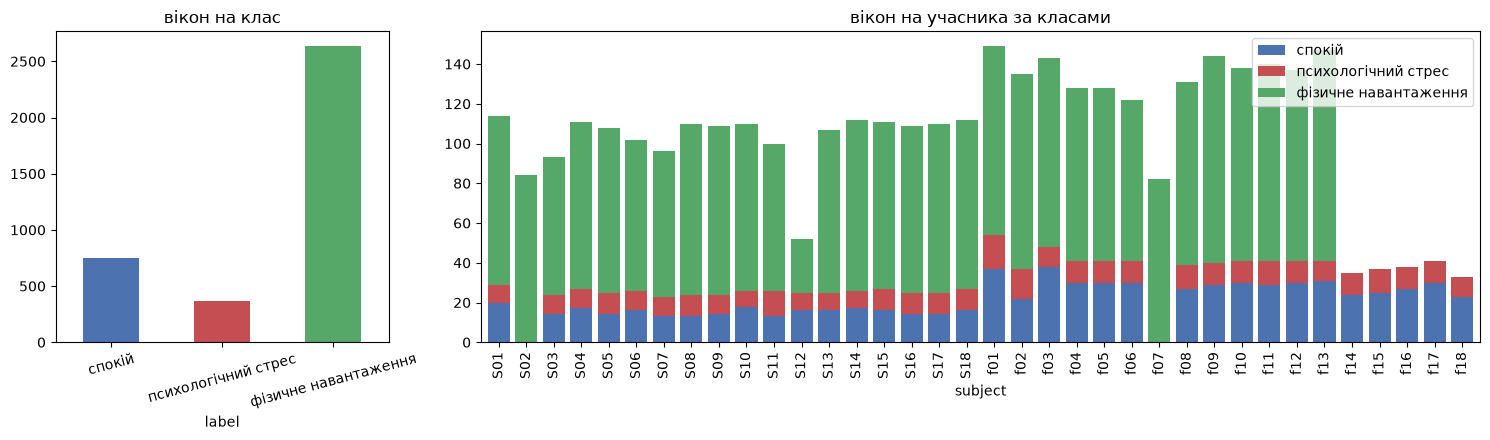

In [7]:
print("відкинуто вікон без надійного пульсу:", dropped)
print("повних дублікатів серед рядків ознак:", int(windows[FEATURES].duplicated().sum()))
balance = pd.crosstab(windows["session"], windows["label"]).rename(columns=dict(enumerate(CLASSES)))
balance.loc["разом"] = balance.sum()
display(balance)

colors = ["#4C72B0", "#C44E52", "#55A868"]
per_subject = pd.crosstab(windows["subject"], windows["label"]).rename(columns=dict(enumerate(CLASSES)))
figure, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1, 3]})
balance.loc["разом"].plot.bar(ax=axes[0], color=colors, rot=15, title="вікон на клас")
per_subject.plot.bar(ax=axes[1], stacked=True, color=colors, rot=90, width=0.8, title="вікон на учасника за класами")
axes[1].legend(loc="upper right")
plt.tight_layout()
plt.show()


In [8]:
windows.groupby("label")[FEATURES].mean().T.round(2).rename(columns=dict(enumerate(CLASSES)))

label,спокій,психологічний стрес,фізичне навантаження
eda_mean,2.81,4.08,8.74
eda_slope,-0.00,0.01,0.01
scr_per_min,6.67,11.52,24.37
scr_amplitude,0.49,1.23,3.68
hr_mean,75.58,81.40,103.01
hr_std,0.87,1.20,1.78
ibi_mean,0.79,0.73,0.59
sdnn,110.10,121.00,152.23
rmssd,127.68,150.78,204.75
temp_mean,32.55,32.58,38.24


### 4.6. Персональне калібрування

Кожна ознака і кожен канал переводяться у відхилення від норми учасника: мінус середнє його стрес-сесії, поділити на стандартне відхилення. Фізичне навантаження при такому калібруванні дає дуже великі відхилення пульсу.


In [9]:
reference = windows[windows["session"] == "STRESS"].groupby("subject")[FEATURES]
means = reference.mean().reindex(windows["subject"]).to_numpy()
deviations = reference.std().reindex(windows["subject"]).to_numpy()

normalized = windows.copy()
normalized[FEATURES] = (windows[FEATURES].to_numpy() - means) / deviations
kept = normalized[FEATURES].notna().all(axis=1).to_numpy()
normalized = normalized[kept].reset_index(drop=True)

raw = raw[kept]
normalized_raw = np.empty_like(raw)
subjects = normalized["subject"].to_numpy()
stress_session = (normalized["session"] == "STRESS").to_numpy()
for subject in np.unique(subjects):
    reference_raw = raw[(subjects == subject) & stress_session]
    channel_means = reference_raw.mean(axis=(0, 2), keepdims=True)
    channel_deviations = reference_raw.std(axis=(0, 2), keepdims=True)
    normalized_raw[subjects == subject] = (raw[subjects == subject] - channel_means) / channel_deviations

X = normalized[FEATURES].to_numpy(dtype=np.float32)
X_raw = normalized_raw.astype(np.float32)
y = normalized["label"].to_numpy()
groups = normalized["subject"].to_numpy()
splits = list(GroupKFold(5).split(X, y, groups))
print("вікон:", len(normalized), " учасників:", normalized["subject"].nunique())

вікон: 3592  учасників: 34


### 4.7. Єдина процедура оцінювання

Модель задається двома функціями, `fit(train_index)` і `predict(model, test_index)`. Процедура проганяє 5 запусків, рахує метрики, заміряє час навчання й inference і пік пам'яті (фоновий потік опитує RSS процесу кожні 20 мс).


In [10]:
class MemoryPeak:
    def __init__(self):
        self.process = psutil.Process()
        self.peak = 0
        self.running = False

    def __enter__(self):
        self.baseline = self.process.memory_info().rss
        self.peak = self.baseline
        self.running = True
        self.thread = threading.Thread(target=self.watch, daemon=True)
        self.thread.start()
        return self

    def watch(self):
        while self.running:
            self.peak = max(self.peak, self.process.memory_info().rss)
            time.sleep(0.02)

    def __exit__(self, *args):
        self.running = False
        self.thread.join()

    @property
    def extra_mb(self):
        return (self.peak - self.baseline) / 1024 ** 2


def evaluate(name, fit, predict, size_bytes, parameters):
    fold_rows = []
    predicted = np.empty(len(y), dtype=int)
    train_time = 0.0
    inference_time = 0.0
    memory_mb = 0.0
    for train_index, test_index in splits:
        with MemoryPeak() as memory:
            started = time.perf_counter()
            model = fit(train_index)
            train_time += time.perf_counter() - started
        memory_mb = max(memory_mb, memory.extra_mb)
        started = time.perf_counter()
        predicted[test_index] = predict(model, test_index)
        inference_time += time.perf_counter() - started
        fold_rows.append({
            "accuracy": accuracy_score(y[test_index], predicted[test_index]),
            "precision": precision_score(y[test_index], predicted[test_index], average="macro", zero_division=0),
            "recall": recall_score(y[test_index], predicted[test_index], average="macro"),
            "macro F1": f1_score(y[test_index], predicted[test_index], average="macro"),
        })
    folds = pd.DataFrame(fold_rows)
    per_class = f1_score(y, predicted, average=None)
    results[name] = {
        "accuracy": folds["accuracy"].mean(),
        "accuracy ±": folds["accuracy"].std(),
        "precision": folds["precision"].mean(),
        "recall": folds["recall"].mean(),
        "macro F1": folds["macro F1"].mean(),
        "macro F1 ±": folds["macro F1"].std(),
        "F1 спокій": per_class[0],
        "F1 стрес": per_class[1],
        "F1 навантаження": per_class[2],
        "підготовка даних, с": preparation_time,
        "час навчання, с": train_time,
        "inference, мс/вікно": inference_time / len(y) * 1000,
        "пам'ять, MB": memory_mb,
        "параметрів": parameters,
        "розмір, KB": size_bytes / 1024,
    }
    predictions[name] = predicted
    fold_scores[name] = folds["macro F1"].to_numpy()
    print(name, "— macro F1 по 5 перевірочних групах:", folds["macro F1"].round(3).tolist())


results = {}
predictions = {}
fold_scores = {}
weights = compute_sample_weight("balanced", y)

## 5. Модель 1: класична ML

XGBoost з налаштуваннями Hongn et al.: 400 дерев глибини 3, швидкість навчання 0,05, підвибірка 0,8 по рядках і стовпцях, ваги класів. Вхід: 12 ручних ознак. Ансамбль неглибоких дерев ловить взаємодії ознак (високий пульс при малому русі означає стрес, при великому навантаження).


In [11]:
def make_xgboost():
    return XGBClassifier(
        n_estimators=400,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        n_jobs=1,
        random_state=SEED,
    )


def fit_xgboost(train_index):
    return make_xgboost().fit(X[train_index], y[train_index], sample_weight=weights[train_index])


def predict_sklearn(model, test_index):
    return model.predict(X[test_index])


xgboost_full = make_xgboost().fit(X, y, sample_weight=weights)
tree_nodes = len(xgboost_full.get_booster().trees_to_dataframe())
evaluate("XGBoost", fit_xgboost, predict_sklearn, len(pickle.dumps(xgboost_full)), tree_nodes)


XGBoost — macro F1 по 5 перевірочних групах: [0.807, 0.815, 0.785, 0.784, 0.817]


## 6. Модель 2: глибока нейронна мережа

Одновимірна згорткова мережа над сирим вікном 5 × 120, без ручних ознак. Три згорткові шари (32, 64, 64 фільтри; ядра 5, 5, 3), після перших двох max-pooling удвічі, далі усереднення по часу, dropout 0,3 і лінійний вихід на 3 класи. Спрощена FCN з Dzieżyc et al. Навчання: Adam 0,001, 30 епох, батч 64, крос-ентропія з вагами класів.


In [12]:
class ConvNet(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv1d(channels, 32, 5, padding=2), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(32, 64, 5, padding=2), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(64, 64, 3, padding=1), nn.ReLU(),
            nn.AdaptiveAvgPool1d(1), nn.Flatten(),
            nn.Dropout(0.3), nn.Linear(64, 3),
        )

    def forward(self, signals):
        return self.layers(signals)


def raw_input(index):
    return (torch.tensor(X_raw[index]),)


def train_network(model, train_index, inputs, epochs, lr, device=torch.device("cpu")):
    torch.manual_seed(0)
    model.to(device)
    counts = np.bincount(y[train_index], minlength=3)
    class_weights = torch.tensor(len(train_index) / (3 * counts), dtype=torch.float32, device=device)
    loss_function = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    tensors = []
    for tensor in inputs(train_index):
        tensors.append(tensor.to(device))
    labels = torch.tensor(y[train_index], device=device)
    model.train()
    for epoch in range(epochs):
        order = torch.randperm(len(train_index))
        for start in range(0, len(train_index), 64):
            batch = order[start:start + 64]
            batch_tensors = []
            for tensor in tensors:
                batch_tensors.append(tensor[batch])
            optimizer.zero_grad()
            loss = loss_function(model(*batch_tensors), labels[batch])
            loss.backward()
            optimizer.step()
    return model.eval()


def predict_network(model, test_index, inputs, device=torch.device("cpu")):
    batch_inputs = []
    for tensor in inputs(test_index):
        batch_inputs.append(tensor.to(device))
    with torch.no_grad():
        output = model(*batch_inputs)
    return output.argmax(dim=1).cpu().numpy()


def count_parameters(model):
    total = 0
    for parameter in model.parameters():
        total += parameter.numel()
    return total


def model_bytes(model):
    buffer = io.BytesIO()
    torch.save(model.state_dict(), buffer)
    return buffer.getbuffer().nbytes


CHANNELS = X_raw.shape[1]


def fit_cnn(train_index):
    torch.manual_seed(0)
    return train_network(ConvNet(CHANNELS), train_index, raw_input, epochs=30, lr=1e-3)


def predict_cnn(model, test_index):
    return predict_network(model, test_index, raw_input)


train_network(ConvNet(CHANNELS), splits[0][0], raw_input, epochs=1, lr=1e-3)
cnn = ConvNet(CHANNELS)
evaluate("згорткова мережа", fit_cnn, predict_cnn, model_bytes(cnn), count_parameters(cnn))

згорткова мережа — macro F1 по 5 перевірочних групах: [0.791, 0.728, 0.759, 0.793, 0.769]


## 7. Модель 3: попередньо навчений Transformer (MOMENT-1) з донавчанням

MOMENT-1 (Goswami et al., ICML 2024): відкрита foundation-модель для часових рядів, encoder T5, попередньо навчений відновлювати замасковані відрізки на Time Series Pile. Ряд довжиною 512 ріжеться на 64 патчі по 8 відліків, канали обробляються незалежно. Узято розмір Small: 35 млн параметрів, 8 блоків encoder, d_model 512. Серед відкритих моделей для часових рядів лише MOMENT має класифікаційну постановку і багатоканальний вхід; Chronos і TimesFM навчені лише на прогноз.

Адаптація. Вікно 5 × 120 лінійно ресемплюється до 512 відліків, тому encoder бачить увесь свій контекст без доповнення нулями. Вихід encoder, 64 патчі × 2560 (d_model × 5 каналів), усереднюється по патчах, зверху лінійна голова з dropout 0,1. Донавчаються останні 2 з 8 блоків encoder, кінцева нормалізація і голова, разом 4,7 млн параметрів; перші 6 блоків і патч-embedding заморожені. Adam 0,0001, 8 епох, батч 64, крос-ентропія з вагами класів, на GPU через MPS; dropout усередині attention вимкнений, бо MPS не підтримує його в scaled_dot_product_attention. Це формат «легке донавчання готової моделі» з методички: повне донавчання 35 млн параметрів на 2900 вікнах перенавчилося б і коштувало б у кілька разів більше часу. Transformer з нуля не навчаємо: на 34 учасниках він не мав би звідки взяти загальні уявлення про форму сигналів.


In [13]:
class Passthrough(nn.Module):
    def forward(self, embeddings, input_mask=None):
        return embeddings


class MomentClassifier(nn.Module):
    def __init__(self, channels, trainable_blocks):
        super().__init__()
        self.moment = MOMENTPipeline.from_pretrained(
            "AutonLab/MOMENT-1-small",
            model_kwargs={
                "task_name": "classification",
                "n_channels": channels,
                "num_class": 3,
                "freeze_encoder": True,
                "freeze_embedder": True,
                "enable_gradient_checkpointing": False,
            },
        )
        self.moment.init()
        self.moment.head = Passthrough()
        for block in self.moment.encoder.block[-trainable_blocks:]:
            for parameter in block.parameters():
                parameter.requires_grad = True
        for parameter in self.moment.encoder.final_layer_norm.parameters():
            parameter.requires_grad = True
        for module in self.moment.encoder.modules():
            if isinstance(getattr(module, "dropout", None), float):
                module.dropout = 0.0
        self.head = nn.Sequential(nn.Dropout(0.1), nn.Linear(self.moment.config.d_model * channels, 3))

    def forward(self, signals):
        resampled = nn.functional.interpolate(signals, size=512, mode="linear", align_corners=False)
        embeddings = self.moment(x_enc=resampled).embeddings
        return self.head(embeddings.mean(dim=1))


def count_trainable(model):
    total = 0
    for parameter in model.parameters():
        if parameter.requires_grad:
            total += parameter.numel()
    return total


def fit_moment(train_index):
    torch.manual_seed(0)
    model = MomentClassifier(CHANNELS, trainable_blocks=2)
    return train_network(model, train_index, raw_input, epochs=8, lr=1e-4, device=DEVICE)


def predict_moment(model, test_index):
    outputs = []
    for start in range(0, len(test_index), 64):
        outputs.append(predict_network(model, test_index[start:start + 64], raw_input, device=DEVICE))
    return np.concatenate(outputs)


moment = MomentClassifier(CHANNELS, trainable_blocks=2)
moment_trainable = count_trainable(moment)
print("параметрів усього:", count_parameters(moment), " донавчається:", moment_trainable)
evaluate("MOMENT-1 (донавчання)", fit_moment, predict_moment, model_bytes(moment), count_parameters(moment))
del moment


/Users/user/Development/Un/ai_principles_methods/.venv/lib/python3.15/site-packages/momentfm/models/moment.py:174: UserWarning: Only reconstruction head is pre-trained. Classification and forecasting heads must be fine-tuned.
  warnings.warn("Only reconstruction head is pre-trained. Classification and forecasting heads must be fine-tuned.")


параметрів усього: 35345091  донавчається: 4728835


/Users/user/Development/Un/ai_principles_methods/.venv/lib/python3.15/site-packages/momentfm/models/moment.py:174: UserWarning: Only reconstruction head is pre-trained. Classification and forecasting heads must be fine-tuned.
  warnings.warn("Only reconstruction head is pre-trained. Classification and forecasting heads must be fine-tuned.")


/Users/user/Development/Un/ai_principles_methods/.venv/lib/python3.15/site-packages/momentfm/models/moment.py:174: UserWarning: Only reconstruction head is pre-trained. Classification and forecasting heads must be fine-tuned.
  warnings.warn("Only reconstruction head is pre-trained. Classification and forecasting heads must be fine-tuned.")


/Users/user/Development/Un/ai_principles_methods/.venv/lib/python3.15/site-packages/momentfm/models/moment.py:174: UserWarning: Only reconstruction head is pre-trained. Classification and forecasting heads must be fine-tuned.
  warnings.warn("Only reconstruction head is pre-trained. Classification and forecasting heads must be fine-tuned.")


/Users/user/Development/Un/ai_principles_methods/.venv/lib/python3.15/site-packages/momentfm/models/moment.py:174: UserWarning: Only reconstruction head is pre-trained. Classification and forecasting heads must be fine-tuned.
  warnings.warn("Only reconstruction head is pre-trained. Classification and forecasting heads must be fine-tuned.")


MOMENT-1 (донавчання) — macro F1 по 5 перевірочних групах: [0.731, 0.624, 0.698, 0.675, 0.672]


## 8. Результати

### 8.1. Якість і ціна

Якість: середнє по 5 групах (± std для accuracy і macro-F1), F1 по класах по зведених прогнозах. Ціна: підготовка даних, навчання за 5 запусків (XGBoost і згорткова мережа на одному потоці CPU, MOMENT на GPU), inference на вікно, пік пам'яті, параметри (для XGBoost вузли дерев), розмір на диску.


In [14]:
summary = pd.DataFrame(results)
quality_rows = ["accuracy", "accuracy ±", "precision", "recall", "macro F1", "macro F1 ±", "F1 спокій", "F1 стрес", "F1 навантаження"]
cost_rows = ["підготовка даних, с", "час навчання, с", "inference, мс/вікно", "пам'ять, MB", "параметрів", "розмір, KB"]
summary.loc[quality_rows].round(3)

,XGBoost,згорткова мережа,MOMENT-1 (донавчання)
accuracy,0.902,0.875,0.819
accuracy ±,0.015,0.024,0.041
precision,0.790,0.762,0.686
recall,0.823,0.803,0.704
macro F1,0.801,0.768,0.680
macro F1 ±,0.016,0.027,0.039
F1 спокій,0.815,0.773,0.686
F1 стрес,0.614,0.557,0.427
F1 навантаження,0.978,0.967,0.931


In [15]:
summary.loc[cost_rows].round(2)

,XGBoost,згорткова мережа,MOMENT-1 (донавчання)
"підготовка даних, с",5.40,5.40,5.40
"час навчання, с",1.01,151.65,2261.92
"inference, мс/вікно",0.00,0.31,12.92
"пам'ять, MB",0.59,0.98,387.52
параметрів,15992.00,23683.00,35345091.00
"розмір, KB",1312.61,95.76,148103.05


Єдина підсумкова таблиця: якість, час, пам'ять і складність поруч. «Навчено параметрів» для MOMENT це 2 останні блоки encoder і голова; «параметрів» вище включає весь encoder.


In [16]:
final = summary.loc[["accuracy", "accuracy ±", "macro F1", "macro F1 ±", "F1 стрес", "час навчання, с", "inference, мс/вікно", "пам'ять, MB", "параметрів", "розмір, KB"]].round(3).astype(object)
final.loc["вхід"] = ["12 ознак", "сире вікно 5 × 120", "сире вікно 5 × 120, ресемпльоване до 512"]
final.loc["архітектура"] = ["400 дерев глибини 3", "3 шари Conv1d + лінійний", "encoder T5 з 8 блоків, донавчено 2 + лінійна голова"]
final.loc["навчено параметрів"] = [tree_nodes, count_parameters(cnn), moment_trainable]
final.loc["GPU"] = ["ні", "ні", "так (MPS)"]
final


,XGBoost,згорткова мережа,MOMENT-1 (донавчання)
accuracy,0.902,0.875,0.819
accuracy ±,0.015,0.024,0.041
macro F1,0.801,0.768,0.68
macro F1 ±,0.016,0.027,0.039
F1 стрес,0.614,0.557,0.427
"час навчання, с",1.015,151.65,2261.917
"inference, мс/вікно",0.004,0.307,12.923
"пам'ять, MB",0.594,0.984,387.516
параметрів,15992.0,23683.0,35345091.0
"розмір, KB",1312.608,95.763,148103.05


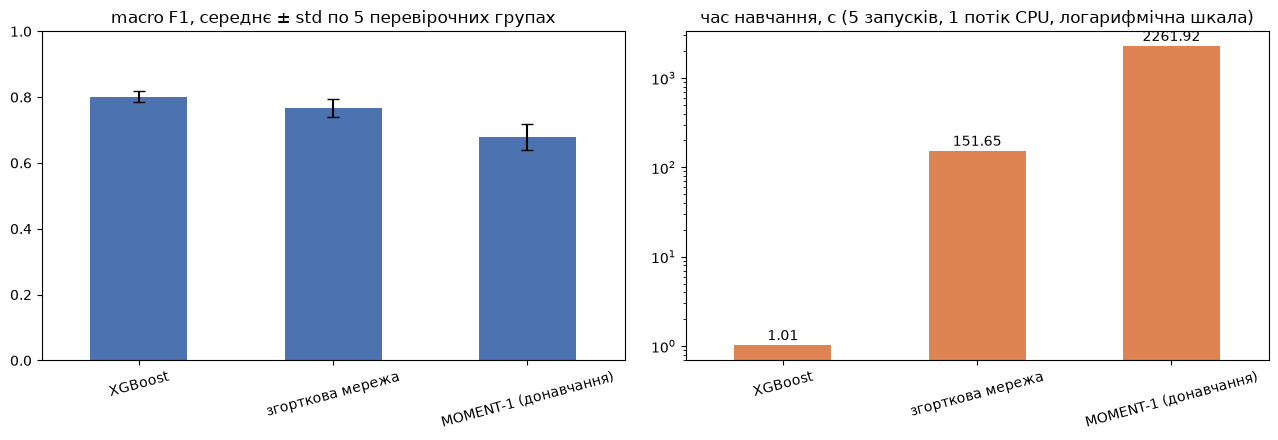

In [17]:
figure, axes = plt.subplots(1, 2, figsize=(13, 4.5))
summary.loc["macro F1"].plot.bar(ax=axes[0], yerr=summary.loc["macro F1 ±"], capsize=4, color="#4C72B0", rot=15, title="macro F1, середнє ± std по 5 перевірочних групах")
axes[0].set_ylim(0, 1)
summary.loc["час навчання, с"].plot.bar(ax=axes[1], color="#DD8452", rot=15, logy=True, title="час навчання, с (5 запусків, 1 потік CPU, логарифмічна шкала)")
for position, value in enumerate(summary.loc["час навчання, с"]):
    axes[1].text(position, value * 1.15, "%.2f" % value, ha="center")
plt.tight_layout()
plt.show()

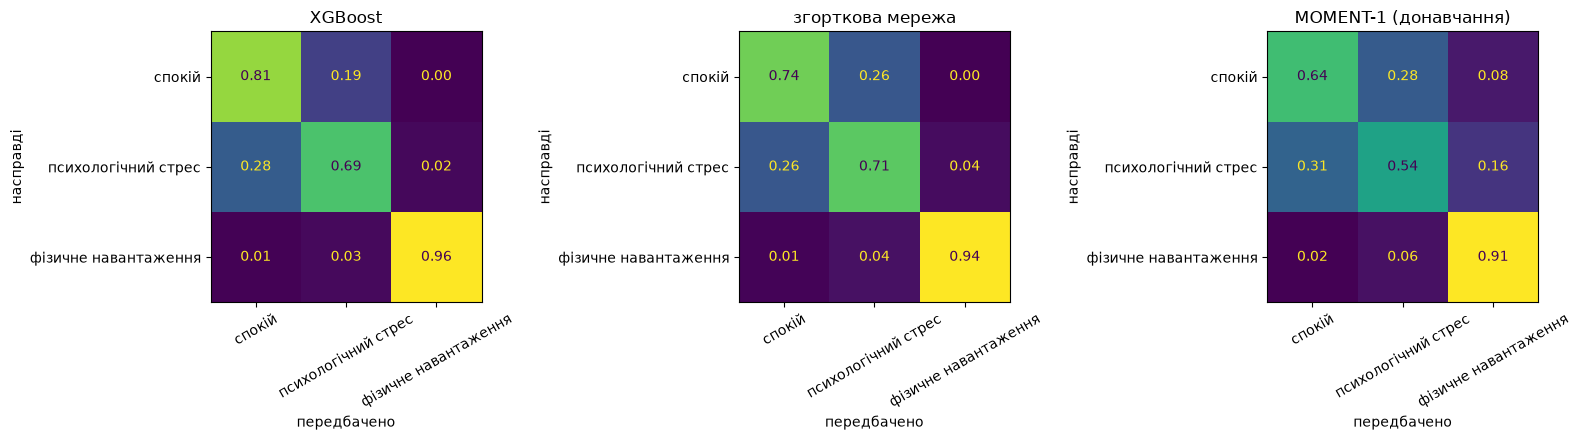

In [18]:
figure, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for axis, (name, predicted) in zip(axes, predictions.items()):
    matrix = confusion_matrix(y, predicted, normalize="true")
    ConfusionMatrixDisplay(matrix, display_labels=CLASSES).plot(ax=axis, colorbar=False, values_format=".2f", xticks_rotation=30)
    axis.set_title(name)
    axis.set_xlabel("передбачено")
    axis.set_ylabel("насправді")
plt.tight_layout()
plt.show()

Матриці плутанини показують, куди саме йдуть помилки. Нижче recall (частка правильно впізнаних вікон) по кожному класу.

In [19]:
recall_rows = {}
for name, predicted in predictions.items():
    recall_rows[name] = recall_score(y, predicted, average=None)
pd.DataFrame(recall_rows, index=CLASSES).round(3)

,XGBoost,згорткова мережа,MOMENT-1 (донавчання)
спокій,0.809,0.737,0.640
психологічний стрес,0.692,0.705,0.538
фізичне навантаження,0.962,0.942,0.914


### 8.2. Стабільність по перевірочних групах

Macro-F1 на кожній з 5 груп учасників. Групи однакові для всіх моделей, тому стовпці можна порівнювати по рядках.


,XGBoost,згорткова мережа,MOMENT-1 (донавчання)
група 1,0.807,0.791,0.731
група 2,0.815,0.728,0.624
група 3,0.785,0.759,0.698
група 4,0.784,0.793,0.675
група 5,0.817,0.769,0.672
середнє,0.801,0.768,0.680
std,0.016,0.027,0.039


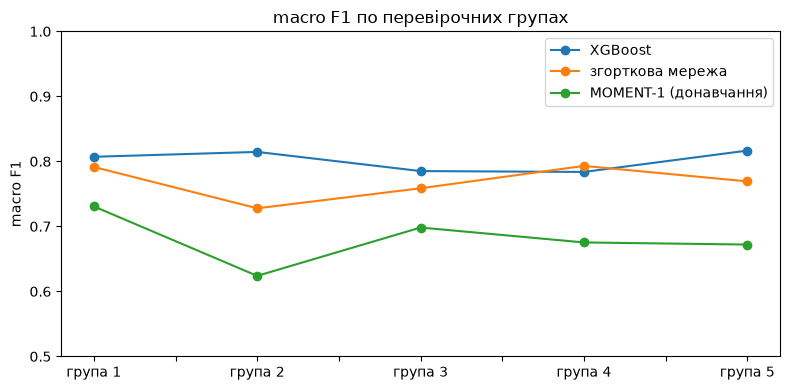

In [20]:
fold_table = pd.DataFrame(fold_scores)
fold_names = []
for number in range(len(fold_table)):
    fold_names.append("група %d" % (number + 1))
fold_table.index = fold_names
fold_means = fold_table.mean()
fold_deviations = fold_table.std()
fold_table.loc["середнє"] = fold_means
fold_table.loc["std"] = fold_deviations
display(fold_table.round(3))

fold_table.iloc[:-2].plot(marker="o", figsize=(8, 4), title="macro F1 по перевірочних групах")
plt.ylim(0.5, 1)
plt.ylabel("macro F1")
plt.tight_layout()
plt.show()


### 8.3. Trade-off: якість проти ціни

Кожна точка це модель: по вертикалі macro-F1 (середнє ± std), по горизонталі ціна в логарифмічній шкалі, розмір маркера пропорційний логарифму розміру моделі на диску. Корисна модель має бути вгорі ліворуч.


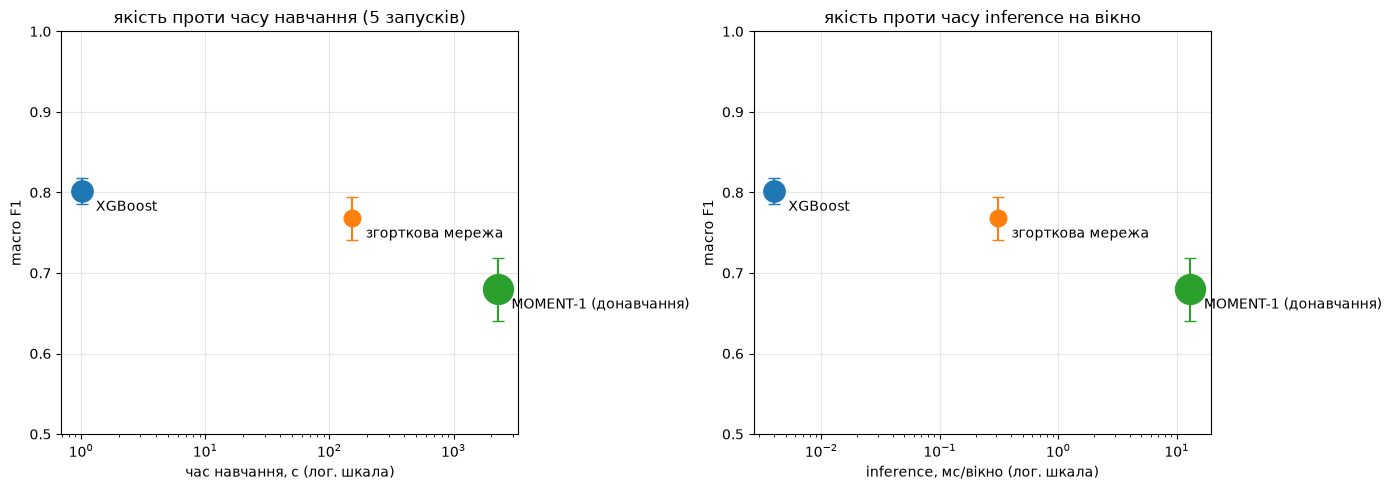

In [21]:
figure, axes = plt.subplots(1, 2, figsize=(14, 5))
for axis, cost in zip(axes, ["час навчання, с", "inference, мс/вікно"]):
    for name in summary.columns:
        x = summary.loc[cost, name]
        quality = summary.loc["macro F1", name]
        marker = 6 + 3 * np.log10(summary.loc["розмір, KB", name])
        axis.errorbar(x, quality, yerr=summary.loc["macro F1 ±", name], fmt="o", markersize=marker, capsize=4, label=name)
        axis.annotate(name, (x, quality), textcoords="offset points", xytext=(10, -14))
    axis.set_xscale("log")
    axis.set_xlabel(cost + " (лог. шкала)")
    axis.set_ylabel("macro F1")
    axis.set_ylim(0.5, 1)
    axis.grid(alpha=0.3)
axes[0].set_title("якість проти часу навчання (5 запусків)")
axes[1].set_title("якість проти часу inference на вікно")
plt.tight_layout()
plt.show()


### 8.4. Важливість ознак (XGBoost)


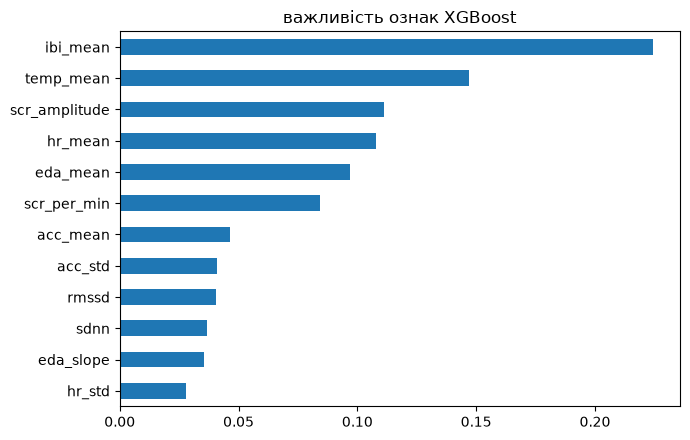

hr_std           0.028
eda_slope        0.036
sdnn             0.037
rmssd            0.040
acc_std          0.041
acc_mean         0.047
scr_per_min      0.084
eda_mean         0.097
hr_mean          0.108
scr_amplitude    0.111
temp_mean        0.147
ibi_mean         0.225
dtype: float32

In [22]:
importance = pd.Series(xgboost_full.feature_importances_, index=FEATURES).sort_values()
importance.plot.barh(figsize=(7, 4.5), title="важливість ознак XGBoost")
plt.tight_layout()
plt.show()
importance.round(3)


### 8.5. Порівняння з літературою

| Робота | Протокол | Їхній результат | Наш найближчий результат |
|---|---|---|---|
| Hongn et al., 2025 (цей датасет) | 10-fold, випадковий поділ, 1 приклад = етап протоколу | 4 класи: acc 84 %, F1 84 % | 3 класи, поділ по учасниках, вікна 30 с: XGBoost acc 90,2 %, macro-F1 80,1 % |
| Schmidt et al., 2018 (WESAD, зап'ястя) | leave-one-subject-out, вікна 60 с | 3 класи: RF acc 76,2, F1 66,3 | 3 класи, поділ по учасниках, вікна 30 с: XGBoost acc 90,2, macro-F1 80,1 |
| Dzieżyc et al., 2020 (WESAD) | 5-fold по учасниках, вікна 60 с | FCN acc 0,79 ± 0,05, F1 0,73 ± 0,07 | згорткова мережа над сирими сигналами: acc 0,88 ± 0,02, macro-F1 0,77 ± 0,03 |
| Goswami et al., 2024 (MOMENT) | linear probing на архіві UCR | точніша за 11 із 16 методів | донавчання 2 останніх блоків encoder на наших сигналах: acc 0,82 ± 0,04, macro-F1 0,68 ± 0,04, нижче за обидві моделі, навчені на задачі |
| Kaya et al., 2026 (6 учасників) | leave-one-participant-out, вікна 10 хв | лише браслет: acc 77,8 %, recall психологічного стресу 50 % | recall психологічного стресу: XGBoost 69 %, згорткова мережа 70 %, MOMENT 54 %; accuracy 82-90 % |

«10-fold» і «5-fold» означають поділ на 10 чи 5 частин, «leave-one-subject-out» і «leave-one-participant-out» означають, що на перевірку по черзі відкладають кожного учасника повністю, «linear probing» означає, що навчається лише лінійна голова над замороженою моделлю.

Прямого аналога нашої постановки (спокій / психологічний стрес / фізичне навантаження з поділом по учасниках) у літературі немає, тому порівняння наближене. Наші числа потрапляють у той самий діапазон або вище, ніж роботи з чесним поділом по учасниках (Schmidt, Dzieżyc, Kaya). Числа Hongn et al. отримані з випадковим поділом, де приклади однієї людини потрапляють і в навчання, і в перевірку, тому напряму з нашими не порівнювані.


## 9. Аналіз

**Якість.** XGBoost: accuracy 0,90 ± 0,02, macro-F1 0,80 ± 0,02. Згорткова мережа: 0,88 ± 0,02 і 0,77 ± 0,03. MOMENT-1: 0,82 ± 0,04 і 0,68 ± 0,04. Відрив XGBoost від мережі (0,03) більший за розкид і повторюється на всіх 5 групах; відрив від MOMENT (0,12) у кілька разів більший за розкид.

**Чому ознаки виграють.** Мережа не бачить ознак і все одно підходить близько (навантаження F1 0,97 проти 0,98, стрес 0,56 проти 0,61). Але на 2900 навчальних вікнах від 27 людей їй бракує даних, щоб самій вивести варіабельність ритму і сплески провідності, які в ознаки закладені з фізіології. Те саме бачили Dzieżyc et al. на WESAD.

**Чому не допомогла попередньо навчена модель.** MOMENT навчався на рядах іншої природи з Time Series Pile, і навіть донавчання двох останніх блоків encoder (4,7 млн параметрів) на 2900 вікнах не наздоганяє мережу, навчену з нуля. Попередній прогін із повністю замороженим encoder і лише лінійною головою (7,7 тис. параметрів, вхід доповнений нулями до 512) дав ту саму macro-F1 0,68 ± 0,04 при accuracy 0,80 ± 0,03. Донавчання підняло accuracy і F1 навантаження (0,90 → 0,93), але не клас стресу: recall стресу 0,54, найгірший серед трьох. Загальні уявлення про форму ряду не містять тонких ознак стресу, а 2900 вікон замало, щоб 35-мільйонна модель їх вивчила.

**Помилки.** Навантаження впізнається майже безпомилково (F1 0,93-0,98). Уся складність у парі спокій / стрес: F1 стресу 0,43-0,61, плутанина в обидва боки. Причини в даних: реакція на завдання запізнюється на десятки секунд, після завдання збудження спадає не одразу, частина учасників майже не реагує. Важливість ознак XGBoost узгоджується з цим: найбільшу вагу мають інтервал між ударами, температура, амплітуда сплесків, пульс і рівень провідності; ознаки руху важать мало.

**Стабільність.** XGBoost std 0,02 (macro-F1 0,78-0,82), мережа 0,03 (0,73-0,79), MOMENT 0,04 (0,62-0,73).

**Ціна.** Підготовка 5 с для всіх. XGBoost: 1 с навчання, 1,3 MB, менше 0,01 мс на вікно, без GPU. Згорткова мережа: 152 с, 96 KB, 0,31 мс. MOMENT: 2262 с (38 хв) навчання на GPU, 148 MB на диску, 388 MB пам'яті, 13 мс на вікно. Кожен наступний рівень коштує на один-два порядки більше часу й якості не додає.


## 10. Висновки

1. Виправданий рівень складності для цієї задачі це класична нелінійна модель над ручними ознаками: XGBoost, accuracy 0,90 ± 0,02, macro-F1 0,80 ± 0,02, 1 с навчання без GPU.
2. Згорткова мережа над сирими сигналами (macro-F1 0,77 ± 0,03) підходить близько, але на 34 учасниках не наздоганяє. Узгоджується з Dzieżyc et al. (2020) і Schmidt et al. (2018).
3. MOMENT-1 з донавчанням двох блоків encoder приросту не дав (0,68 ± 0,04, стільки ж, скільки із замороженим encoder): попереднє навчання не покриває сигнали браслета, а ціна (38 хв навчання на GPU, 148 MB, 13 мс на вікно) для носимого пристрою непридатна.
4. Навантаження відділяється легко (F1 0,93-0,98), стрес від спокою важко (0,43-0,61). Це межа даних: запізніла й неоднакова реакція на лабораторні завдання, короткі вікна.
5. Протокол має ділити дані по учасниках. Числа Hongn et al. з випадковим поділом із нашими не порівнювані.
6. Обмеження: 34 учасники, лабораторний стрес, гіперпараметри без валідаційної частини, MOMENT донавчений частково (2 з 8 блоків) і на GPU, решта на CPU.
7. Далі: BVP на 64 Гц для мереж, контекст сусідніх вікон, повне донавчання MOMENT або foundation-модель, навчена саме на фізіологічних сигналах, більше учасників через об'єднання з WESAD.
